# Task 2 - Multilayer Perceptron (MLP)

This notebook implements the MLP part of Task 2: multiclass classification of the
nine power-quality disturbances (PQDs). The feature CSV files generated in Task 1
are loaded for all five noise conditions: noiseless, 50 dB, 40 dB, 30 dB, and
20 dB.

The workflow is deliberately leakage-safe:

1. combine the SNR datasets and keep the SNR as metadata;
2. make one stratified train/validation split;
3. fit standardisation only on the training partition;
4. select the MLP configuration with stratified 5-fold cross-validation on the
   training partition;
5. fit the selected model on all training data and evaluate once on validation
   data;
6. report overall and per-SNR accuracy, precision, recall, and F1 score.

The held-out validation set is not used for model selection.


In [ ]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    make_scorer,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split, RandomizedSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 12
TEST_SIZE = 0.20
CV_SPLITS = 5

SNR_LEVELS = ["SNR_noiseless", "SNR_50db", "SNR_40db", "SNR_30db", "SNR_20db"]
CLASS_NAMES = [
    "Normal",
    "Sag",
    "Swell",
    "Interruption",
    "Harmonics",
    "Sag_harmonics",
    "Swell_harmonics",
    "Transient",
    "Flicker",
]

NORMAL_LABEL = "Normal"
normal_precision_scorer = make_scorer(
    precision_score,
    labels=[NORMAL_LABEL],
    average="macro",
    zero_division=0,
)

# The Task 1 positional convention maps raw columns to the F1-F8 names below.
FEATURE_COLUMNS = ["F1", "F2", "F3", "F4", "F5", "F6", "F7", "F8"]
RAW_TO_FEATURE = {
    "avg abs": "F2",
    "sd": "F3",
    "max": "F4",
    "min": "F5",
    "no. pks": "F6",
    "sd fma": "F7",
    "sd fma 3": "F1",
    "no. pt near 0": "F8",
            }

# Make the notebook independent of the directory from which Jupyter was started.
current = Path.cwd().resolve()
DATA_ROOT = next(
    (path / "Code" / "data" for path in [current, *current.parents]
     if (path / "Code" / "data").is_dir()),
    None,
)
if DATA_ROOT is None:
    raise FileNotFoundError(
        "Could not find Code/data. Run this notebook inside the project "
        "repository or update DATA_ROOT."
    )
print(f"Using data from: {DATA_ROOT}")


Using data from: /Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/01 Machine Learning/05 Project/EE4C12---Machine-Learning-Project/Code/data


## 1. Load and label all SNR datasets

Each CSV contains one row per signal sample. The filename is the PQD class label;
the first CSV column is an index and is intentionally ignored. SNR is retained
in a separate column so that robustness can be inspected after the final
evaluation.


In [8]:
def load_feature_data(data_root):
    frames = []
    for snr in SNR_LEVELS:
        snr_dir = data_root / snr
        if not snr_dir.is_dir():
            raise FileNotFoundError(f"Missing SNR directory: {snr_dir}")
        for csv_path in sorted(snr_dir.glob("*.csv")):
            label = csv_path.stem
            if label not in CLASS_NAMES:
                raise ValueError(f"Unexpected class file: {csv_path.name}")
            frame = pd.read_csv(csv_path).rename(columns=RAW_TO_FEATURE)
            missing = set(FEATURE_COLUMNS) - set(frame.columns)
            if missing:
                raise ValueError(f"{csv_path} is missing features: {sorted(missing)}")
            frame = frame[FEATURE_COLUMNS].copy()
            frame["label"] = label
            frame["snr"] = snr.removeprefix("SNR_")
            frames.append(frame)
    return pd.concat(frames, ignore_index=True)


dataset = load_feature_data(DATA_ROOT)
X = dataset[FEATURE_COLUMNS]
y = dataset["label"]
print(f"Loaded {len(dataset):,} samples and {X.shape[1]} features.")
# display(dataset.groupby(["snr", "label"]).size().unstack(fill_value=0))


Loaded 6,705 samples and 8 features.


## 2. Create a stratified train/validation split

Stratification preserves the class proportions in both partitions. The pipeline
below places `StandardScaler` before the MLP, which is important because the
features have very different numerical scales. The scaler is fitted separately
inside every cross-validation fold and later on the training partition only.


In [9]:
X_train, X_valid, y_train, y_valid, snr_train, snr_valid = train_test_split(
    X,
    y,
    dataset["snr"],
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)
print(f"Training samples: {len(X_train):,}")
print(f"Validation samples: {len(X_valid):,}")


Training samples: 5,364
Validation samples: 1,341


## 3. Cross-validate the MLP on the training partition

The candidate hidden-layer sizes and regularisation values are intentionally
small enough to run on this dataset while still testing meaningful alternatives.
The selection metric is macro-F1: every PQD contributes equally, including
classes that are harder to recognise. Accuracy is reported as a complementary
index.


In [ ]:
constant_candidates = [
    {"hidden_layer_sizes": (32, 32, 32)},
    {"hidden_layer_sizes": (64, 64, 64)},
    {"hidden_layer_sizes": (128, 128, 128)}
]

inverted_funnel_candidates = [
    {"hidden_layer_sizes": (32, 64, 32)},
    {"hidden_layer_sizes": (64, 128, 64)},
    {"hidden_layer_sizes": (128, 256, 128)}
]

shallow_wide_candidates = [
    {"hidden_layer_sizes": (256, )},
    {"hidden_layer_sizes": (512, )},
    {"hidden_layer_sizes": (1024, )}
]

narrow_deep_candidates = [
    {"hidden_layer_sizes": (32, 32, 32, 32)},
    {"hidden_layer_sizes": (64, 64, 64, 64)},
    {"hidden_layer_sizes": (128, 128, 128, 128)}
]

funnel_candidates = [
    {"hidden_layer_sizes": (128, 64, 32)},
    {"hidden_layer_sizes": (256, 128, 64)},
    {"hidden_layer_sizes": (512, 256, 128)}
]

candidates = (
    constant_candidates
    + inverted_funnel_candidates
    + shallow_wide_candidates
    + narrow_deep_candidates
    + funnel_candidates
)

alphas = [1e-4, 1e-3, 1e-2]


cv = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []



################# Grid Search for MLP Hyperparameters #################
for alpha in alphas:
    for candidate in candidates:
        pipeline = Pipeline(
            [
                ("scaler", StandardScaler()),
                (
                    "mlp",
                    MLPClassifier(
                        **candidate,
                        activation="relu",
                        alpha=alpha,
                        solver="adam",
                        batch_size=64,
                        learning_rate_init=1e-3,
                        max_iter=500,
                        early_stopping=True,
                        validation_fraction=0.15,
                        n_iter_no_change=25,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        )
        scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring={
                "accuracy": "accuracy",
                "precision_macro": "precision_macro",
                "recall_macro": "recall_macro",
                "f1_macro": "f1_macro",
                "normal_precision": normal_precision_scorer,
            },
            n_jobs=-1,
        )
        cv_rows.append(
            {
                **candidate,
                "alpha": alpha,
                "accuracy_mean": scores["test_accuracy"].mean(),
                "precision_macro_mean": scores["test_precision_macro"].mean(),
                "recall_macro_mean": scores["test_recall_macro"].mean(),
                "f1_macro_mean": scores["test_f1_macro"].mean(),
                "f1_macro_std": scores["test_f1_macro"].std(),
                "normal_precision_mean": scores["test_normal_precision"].mean(),
            }
        )

cv_results = pd.DataFrame(cv_rows).sort_values(
    ["normal_precision_mean", "f1_macro_mean"], ascending=False
)
display(cv_results.reset_index(drop=True))
best_params = cv_results.iloc[0][["hidden_layer_sizes", "alpha"]].to_dict()
print("Selected configuration:", best_params)


,hidden_layer_sizes,alpha,accuracy_mean,precision_macro_mean,recall_macro_mean,f1_macro_mean,f1_macro_std,normal_precision_mean
0,"(256, 128, 64)",0.0100,0.980611,0.980883,0.980608,0.980560,0.004508,0.946017
1,"(64, 128, 64)",0.0100,0.981730,0.981945,0.981734,0.981725,0.001389,0.945146
2,"(32, 32, 32, 32)",0.0100,0.979679,0.980011,0.979678,0.979688,0.001954,0.941953
3,"(256, 128, 64)",0.0010,0.981731,0.981977,0.981730,0.981703,0.004735,0.941625
4,"(256, 128, 64)",0.0001,0.979866,0.980079,0.979862,0.979830,0.004776,0.941164
5,"(128, 64, 32)",0.0001,0.982476,0.982717,0.982479,0.982493,0.002466,0.940720
6,"(128, 256, 128)",0.0100,0.979305,0.979559,0.979314,0.979313,0.003168,0.940236
7,"(128, 256, 128)",0.0001,0.979120,0.979481,0.979119,0.979128,0.001668,0.939129
8,"(64, 128, 64)",0.0010,0.979493,0.979796,0.979488,0.979504,0.002114,0.938935
9,"(512, 256, 128)",0.0100,0.982849,0.983237,0.982848,0.982871,0.002150,0.938376


Selected configuration: {'hidden_layer_sizes': (256, 128, 64), 'alpha': 0.01}


In [ ]:
################# Random Search for MLP Hyperparameters #################

# Define the hyperparameter search space
param_distributions = {
    'hidden_layer_sizes': [(50,), (100,), (50, 50), (100, 50), (64, 32)],
    'activation': ['relu', 'tanh'],
    'solver': ['adam', 'lbfgs'],
    'alpha': [1e-5, 1e-4, 1e-3, 1e-2],
    'learning_rate_init': [1e-4, 1e-3, 1e-2],
    'max_iter': [500]
}

# Initialize the base classifier with early stopping enabled
mlp = MLPClassifier(random_state=42, early_stopping=True)

# Set up Randomized Search
random_search = RandomizedSearchCV(
    estimator=mlp,
    param_distributions=param_distributions,
    n_iter=20,           # Number of parameter settings sampled
    cv=5,                # 5-fold cross-validation
    scoring='f1_macro',  # Recommended if PQD classes are imbalanced
    n_jobs=-1,
    random_state=42
)

results_df = pd.DataFrame(random_search.cv_results_)
print("Randomized Search Results:")
print(results_df[['params', 'mean_test_score', 'std_test_score']].sort_values(by='mean_test_score', ascending=False).head(10))

## 4. Fit the selected MLP and evaluate on held-out validation data

The following metrics are the final validation results. Macro-averaging gives
each class equal weight; weighted-F1 additionally reflects the class support.
The confusion matrix shows which PQDs are confused with one another.


,Metric,Value
0,Accuracy,0.978374
1,Macro precision,0.979190
2,Macro recall,0.978374
3,Macro F1,0.978513
4,Weighted F1,0.978513


,precision,recall,f1-score,support
Normal,0.894410,0.966443,0.929032,149.0
Sag,1.000000,0.966443,0.982935,149.0
Swell,1.000000,0.993289,0.996633,149.0
Interruption,0.973856,1.000000,0.986755,149.0
Harmonics,1.000000,1.000000,1.000000,149.0
Sag_harmonics,1.000000,1.000000,1.000000,149.0
Swell_harmonics,1.000000,1.000000,1.000000,149.0
Transient,0.972222,0.939597,0.955631,149.0
Flicker,0.972222,0.939597,0.955631,149.0


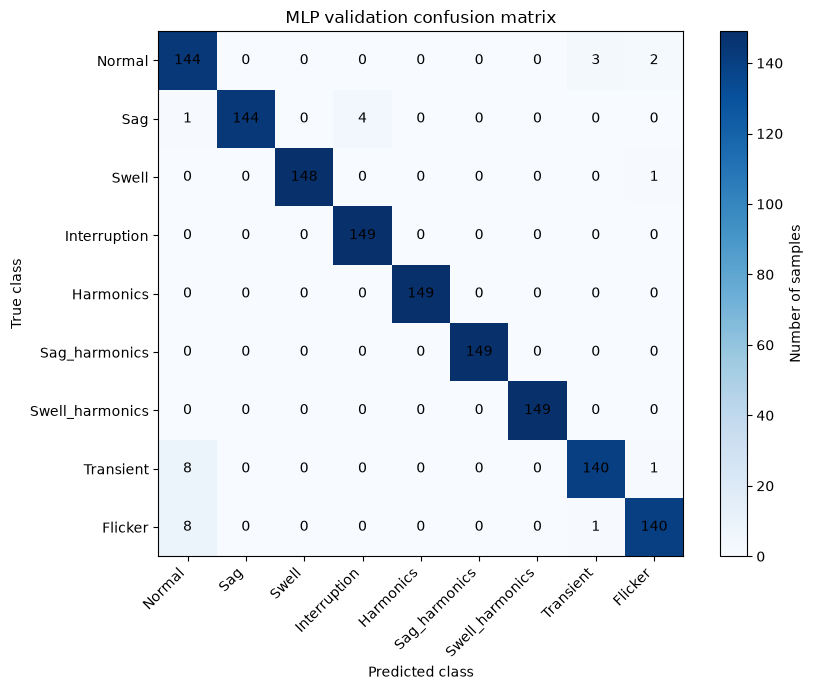

In [11]:
final_model = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "mlp",
            MLPClassifier(
                hidden_layer_sizes=best_params["hidden_layer_sizes"],
                alpha=float(best_params["alpha"]),
                activation="relu",
                solver="adam",
                batch_size=64,
                learning_rate_init=1e-3,
                max_iter=500,
                early_stopping=True,
                validation_fraction=0.15,
                n_iter_no_change=25,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_valid)

overall_metrics = pd.DataFrame(
    {
        "Metric": ["Accuracy", "Macro precision", "Macro recall", "Macro F1", "Weighted F1"],
        "Value": [
            accuracy_score(y_valid, y_pred),
            precision_score(y_valid, y_pred, average="macro", zero_division=0),
            recall_score(y_valid, y_pred, average="macro", zero_division=0),
            f1_score(y_valid, y_pred, average="macro", zero_division=0),
            f1_score(y_valid, y_pred, average="weighted", zero_division=0),
        ],
    }
)
display(overall_metrics)

report = pd.DataFrame(
    classification_report(
        y_valid, y_pred, labels=CLASS_NAMES, output_dict=True, zero_division=0
    )
).T
display(report.loc[CLASS_NAMES, ["precision", "recall", "f1-score", "support"]])

fig, ax = plt.subplots(figsize=(9, 7))
confusion = confusion_matrix(y_valid, y_pred, labels=CLASS_NAMES)
image = ax.imshow(confusion, cmap="Blues")
fig.colorbar(image, ax=ax, label="Number of samples")
for row in range(confusion.shape[0]):
    for column in range(confusion.shape[1]):
        ax.text(column, row, confusion[row, column], ha="center", va="center")
ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title("MLP validation confusion matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## 5. Evaluate robustness at each SNR level

This is a diagnostic breakdown of the same held-out validation predictions.
It does not refit the model for each SNR, so the numbers describe how one MLP
trained on the complete range of noise conditions behaves as contamination
increases.


In [12]:
# validation_results = dataset.loc[X_valid.index, ["snr"]].copy()
# validation_results["label"] = y_valid
# validation_results["prediction"] = y_pred

# snr_rows = []
# for snr, group in validation_results.groupby("snr", sort=False):
#     snr_rows.append(
#         {
#             "SNR": snr,
#             "Samples": len(group),
#             "Accuracy": accuracy_score(group["label"], group["prediction"]),
#             "Macro precision": precision_score(
#                 group["label"], group["prediction"], labels=CLASS_NAMES,
#                 average="macro", zero_division=0
#             ),
#             "Macro recall": recall_score(
#                 group["label"], group["prediction"], labels=CLASS_NAMES,
#                 average="macro", zero_division=0
#             ),
#             "Macro F1": f1_score(
#                 group["label"], group["prediction"], labels=CLASS_NAMES,
#                 average="macro", zero_division=0
#             ),
#         }
#     )
# snr_results = pd.DataFrame(snr_rows)
# display(snr_results)

# ax = snr_results.set_index("SNR")[["Accuracy", "Macro F1"]].plot(
#     kind="bar", ylim=(0, 1.05), figsize=(9, 4), rot=0
# )
# ax.set_ylabel("Score")
# ax.set_title("MLP performance by SNR")
# ax.grid(axis="y", alpha=0.3)
# plt.tight_layout()
# plt.show()


## Interpretation

Use the cross-validation table to justify the selected architecture and use the
validation metrics, class report, confusion matrix, and SNR table to discuss
effectiveness. For the full Task 2 submission, this MLP should be compared with
the Decision Tree and Random Forest classifiers using the same split and metric
definitions. A higher macro-F1 indicates better balanced multiclass recognition.
